# Practice PS07: Outlier analysis

<font size="+2" color="#2680EB">Additional results: faster method to find all depths</font>

Done at the end of the notebook.

Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB"> anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">11/11/2026</font>

In [67]:
# LEAVE THIS CELL AS-IS
import csv
import io
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

# 0. Dataset

In [68]:
# LEAVE AS-IS

# Load both datasets
dft = pd.read_csv('annthyroid.csv', sep=',')
dfc = pd.read_csv('cardio.csv', sep=',')
dfb = pd.read_csv('breast_cancer.csv', sep=',')

# 1. Exploratory analysis

In [69]:
# LEAVE AS-IS

def print_normal_abnormal(df, dataset_name):
    print(f"The {dataset_name} dataset contains {len(df)} patients")
    n_normal = len(df[df['result'] == 'normal'])
    n_abnormal = len(df[df['result'] == 'abnormal'])
    print(" Normal   : %d (%.2f%%)" % ( n_normal, 100*n_normal / (n_normal + n_abnormal)))
    print(" Abnormal : %d (%.2f%%)" % ( n_abnormal, 100*n_abnormal / (n_normal + n_abnormal)))
    print()
    
print_normal_abnormal(dft, "Thyroid")
print_normal_abnormal(dfc, "Cardiotocography")
print_normal_abnormal(dfb, "Breast Cancer")

The Thyroid dataset contains 7200 patients
 Normal   : 6666 (92.58%)
 Abnormal : 534 (7.42%)

The Cardiotocography dataset contains 1831 patients
 Normal   : 1655 (90.39%)
 Abnormal : 176 (9.61%)

The Breast Cancer dataset contains 699 patients
 Normal   : 458 (65.52%)
 Abnormal : 241 (34.48%)



## 1.1. Visual inspection for class separation <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function to display scatter plots for every pair of features.**</font>

In [70]:

def print_scatter_matrix(dataset, dataset_name, color_normal, color_abnormal):
    print(f"Scatter matrix for the {dataset_name} dataset.")

    # YOUR ANSWER HERE
     # Define the colors for each class
    color_code = {'normal': color_normal, 'abnormal': color_abnormal}
    # Create a scatter matrix for all features
    sns.pairplot(dataset, hue='result', palette=color_code, height=2.0, aspect=1.0)
 
    
    plt.show()

Scatter matrix for the Thyroid dataset.


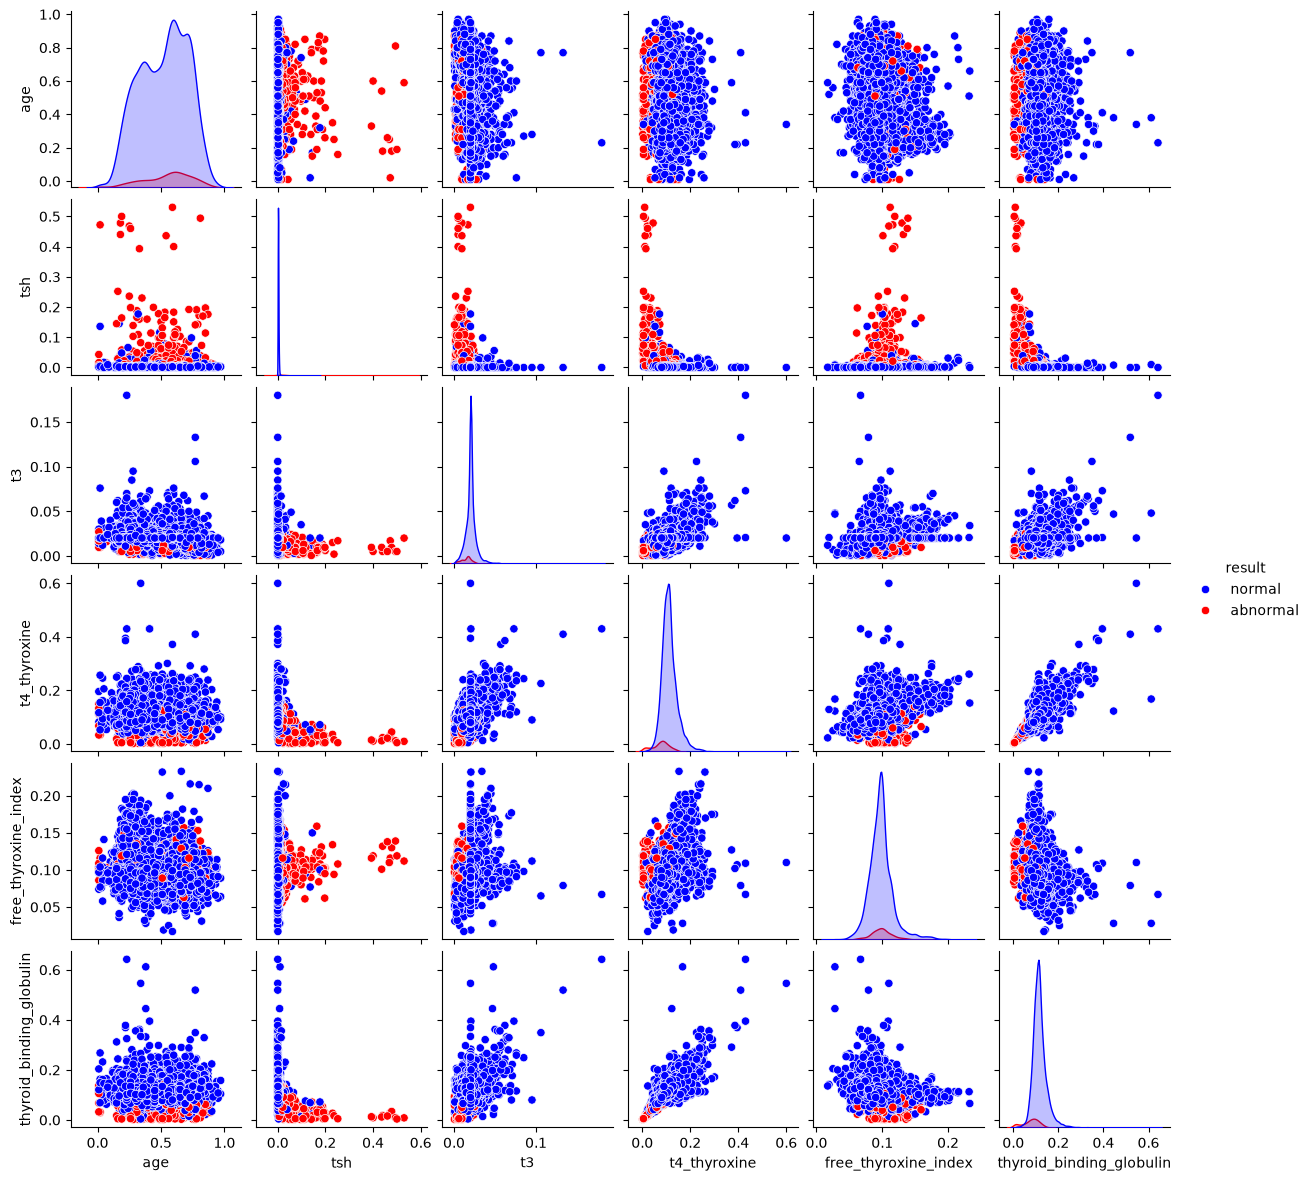

Scatter matrix for the Breast cancer dataset.


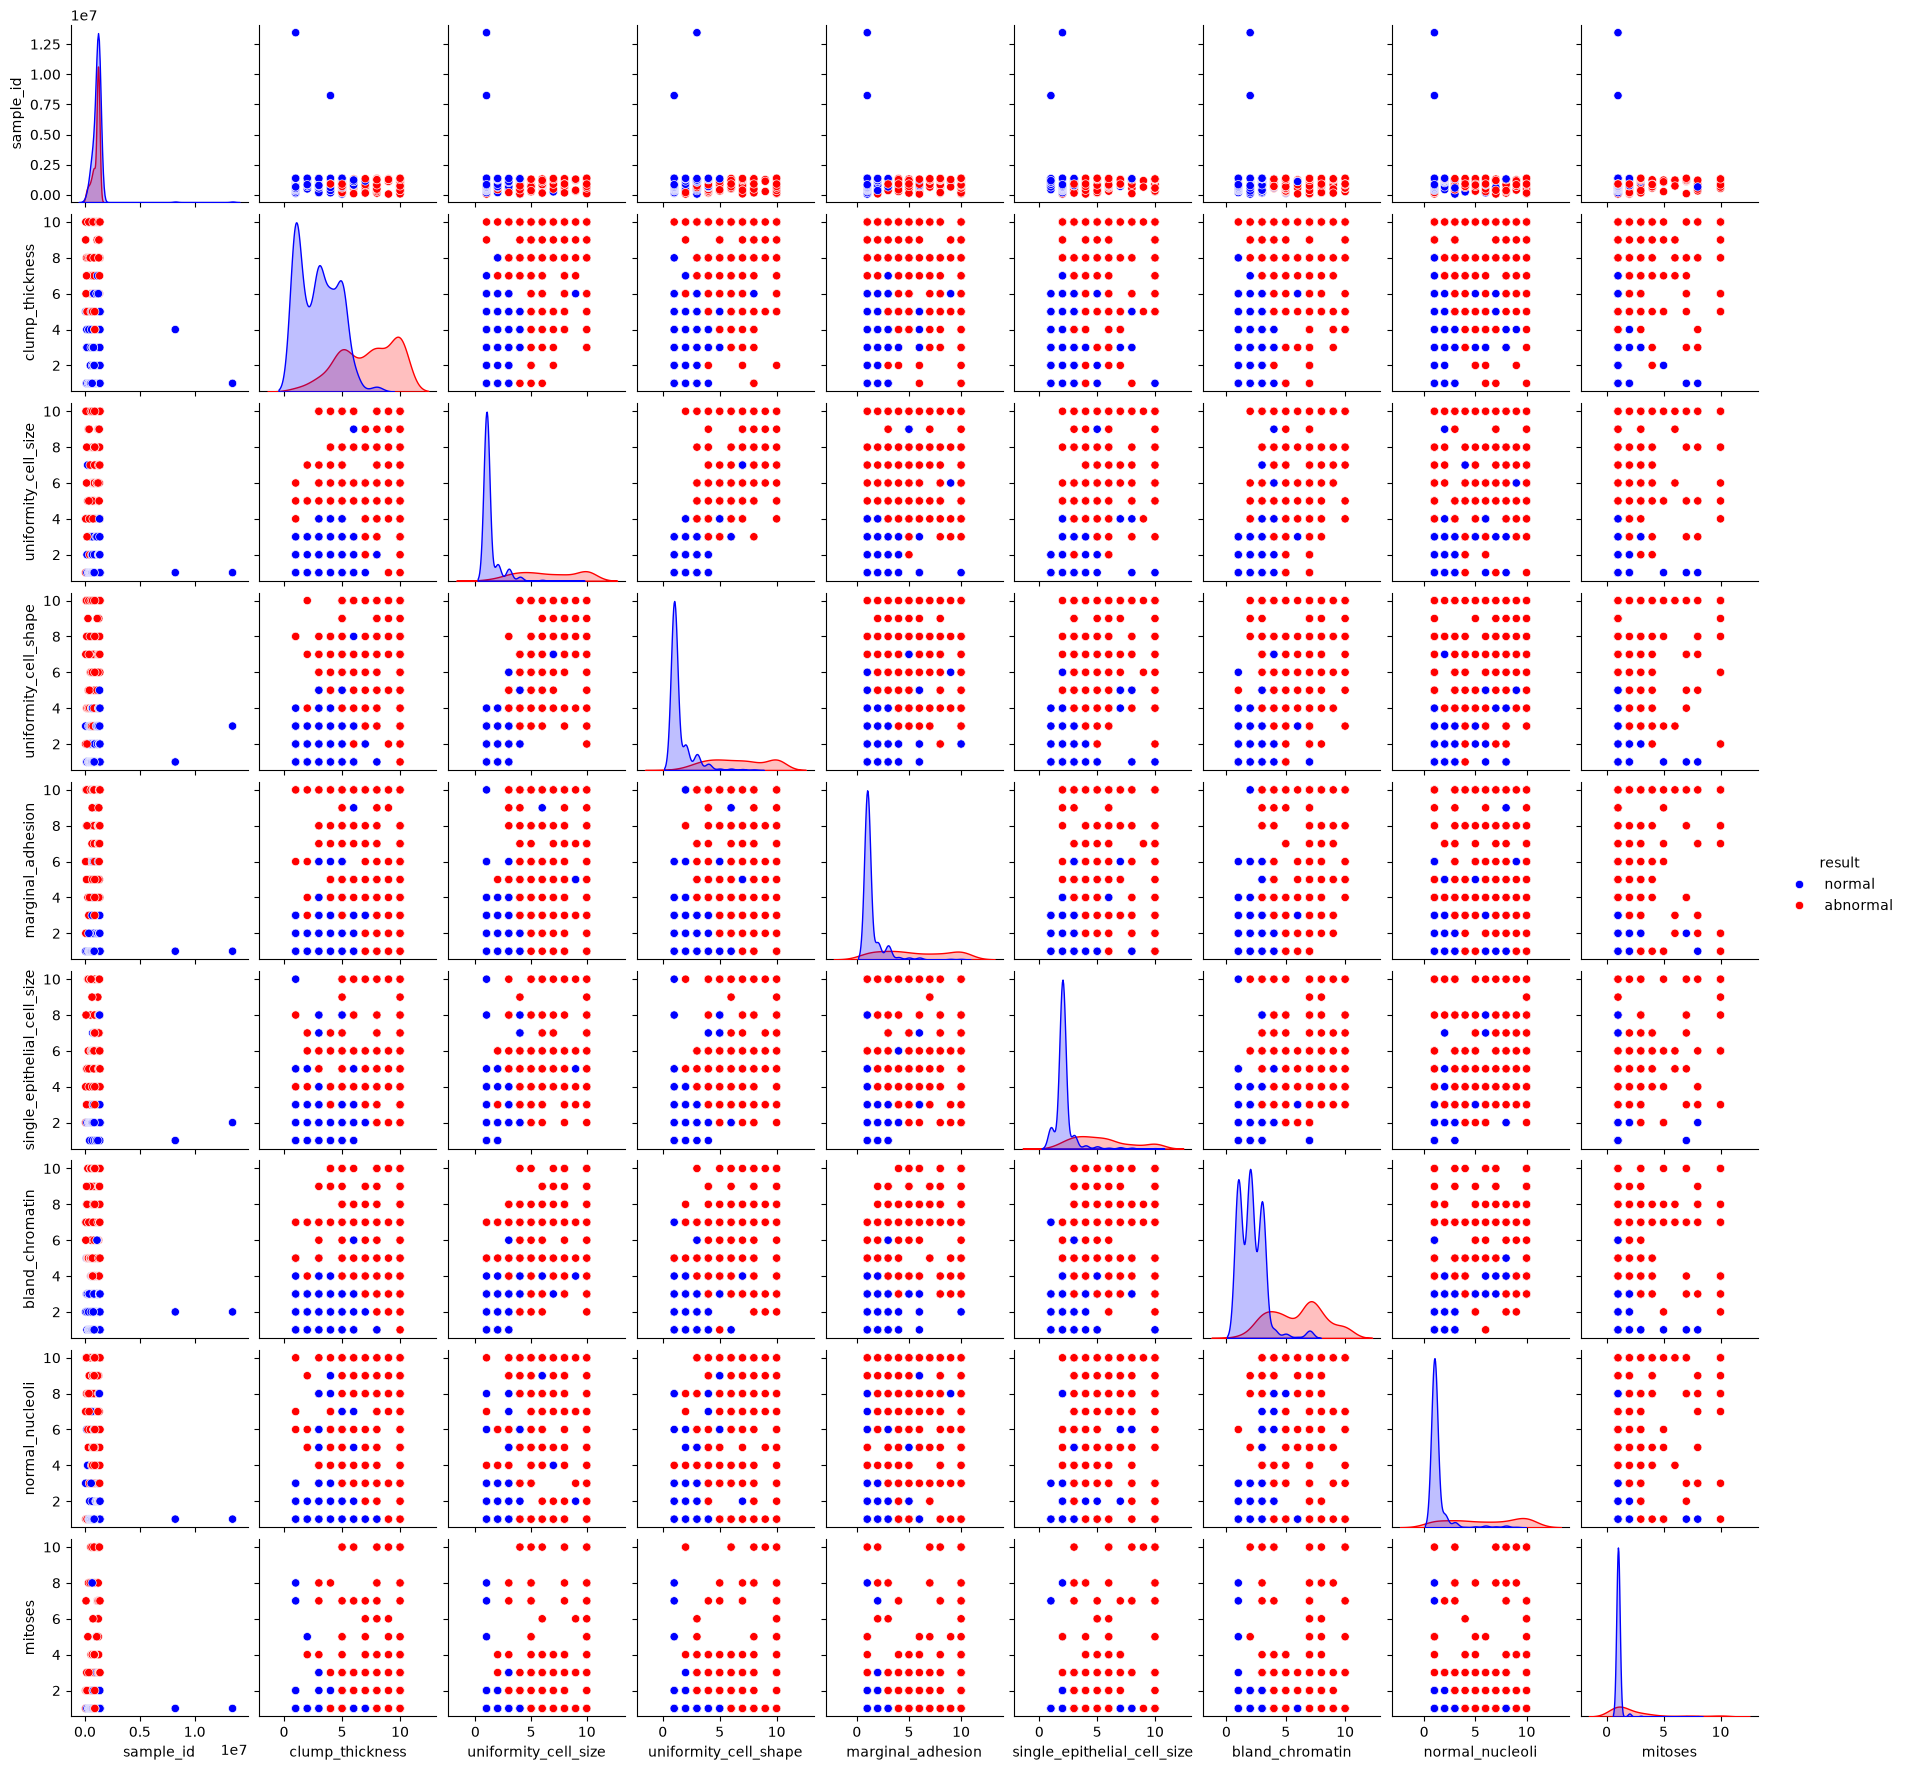

In [71]:
# LEAVE AS-IS

print_scatter_matrix(dft, 'Thyroid', 'blue', 'red')
print_scatter_matrix(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of combinations of two features.** Answer these questions.</font>

**Answer:**

What do the plots in the diagonal represent?

* The diagonal plots show the distribution of each feature using Kernel Density Estimation (KDE). This method combines kernels around individual observations to create a smooth density curve, allowing us to compare normal and abnormal patients because higher density areas indicate where observations are more concentrated.

In the case of the *Thyroid* dataset, is there any single feature that provides good separation between classes, which one (if any)? Are there pairs of features that can do this to some extent? Can you provide an example of such pair of features? In each case (single feature and pair of features), is there complete separability, or some overlap?

* In the Thyroid dataset, features such as tsh and t4_thyroxine provide a relatively good separation between the two classes. Abnormal patients tend to have more extreme values, while normal patients are more concentrated around lower values. However, there is still some overlap, so the separation is not complete.

* Regarding pairs of features, tsh and t4_thyroxine, or free_thyroxine_index and t3, help to separate the classes better than a single feature alone. Combining these features makes it easier to distinguish between normal and abnormal patients. In both cases, there is no complete separability because some overlap remains.

And in the case of the *Breast cancer* dataset?

* In the Breast cancer dataset, many single features provide good separation, such as uniformity_cell_size and uniformity_cell_shape. Pairs of these features (like uniformity_cell_size vs uniformity_cell_shape) show a very clear separation between normal and abnormal tumors. Just like the Thyroid dataset, the separation is very strong but not completely perfect, there is still a small amount of overlap.

In the *Breast cancer* dataset, many scatterplots look like a grid/lattice, why do you think that happens?

* This happens because the values in this dataset are discrete integer values (mostly from 1 to 10) instead of continuous decimal numbers. Since the data points can only be placed on exact whole numbers, they line up in straight rows and columns, creating a grid shape.

## 1.2. Visual inspection for outliers  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function that uses PCA to project into two dimensions.** The function should project all features except the last one, which contains the result (normal or abnormal).</font>

In [72]:
def project_2D(df):

    # Extract features, which appear in all columns except the last one
    features = df.iloc[:, :-1]
    
    # Extract the last column, which contains the label
    result = df.iloc[:, -1]
    
    # Replace '?' values (present in one of the datasets) with NULL
    features = features.replace('?', np.nan)
    result = result.replace('?', np.nan)

    # Remove rows with NaN values in the features or the result
    valid_rows = features.notnull().all(axis=1) & result.notnull()
    features = features[valid_rows]
    result = result[valid_rows]
    
    # YOUR CODE HERE
    # Apply PCA to project to 2 dimensions
    pca = PCA(n_components=2)
    projected_features = pca.fit_transform(features)
    # Create output dataframe with projected dimensions named X and Y and the result
    output = pd.DataFrame(projected_features, columns=['X', 'Y'], index=features.index)
    output['result'] = result


    
    return output

<font size="+1" color="#2680EB">**Plot the projected datasets.** Reuse the color mapping you defined above.</font>

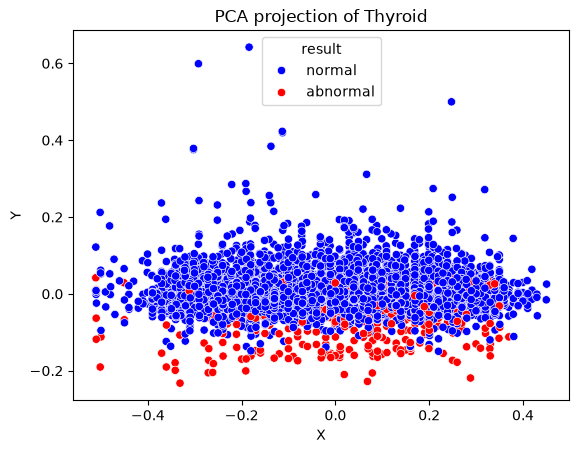

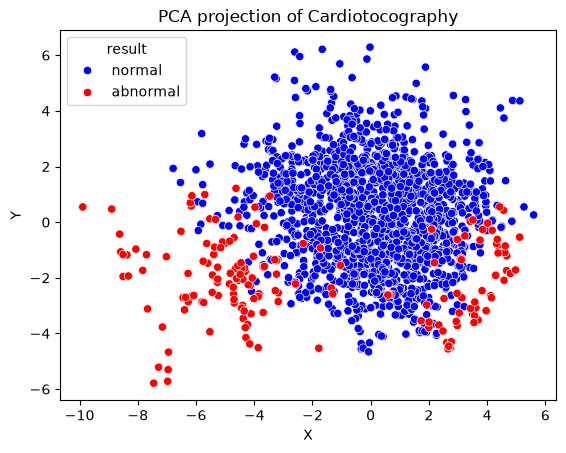

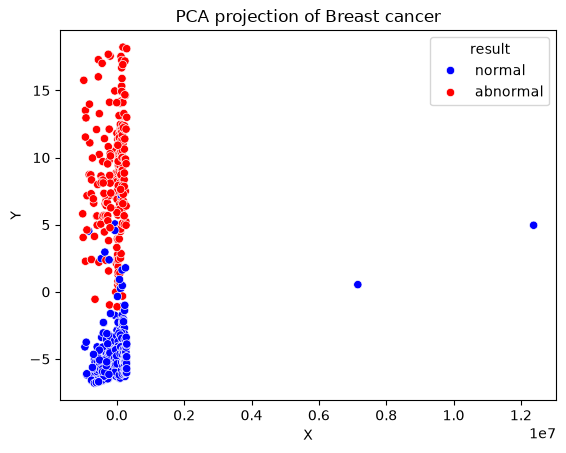

In [73]:
def plot_projected_dataset(dataset, dataset_name, color_normal, color_abnormal):
    df_projected = project_2D(dataset)

    # Create a color palette
    color_code = {'normal': color_normal, 'abnormal': color_abnormal}

    # Plot a scatter plot of df_projected with X on the x-axis and Y on the y-axis
    # Color points by the result column using seaborn
    # YOUR CODE HERE
    sns.scatterplot(data=df_projected, x='X', y='Y', hue='result', palette=color_code)
    plt.title(f'PCA projection of {dataset_name}')
    plt.show()

plot_projected_dataset(dft, 'Thyroid', 'blue', 'red')
plot_projected_dataset(dfc, 'Cardiotocography', 'blue', 'red')
plot_projected_dataset(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of the projected datasets.** Answer these questions.</font>

**Answer:**

In the case of the *Thyroid* dataset, would you say that the abnormal points are *outliers*? Are they extreme values? Briefly justify your answer.

* In the Thyroid dataset, the abnormal points form a distinct horizontal group below the main cluster of normal points. Although there is some overlap between the two classes, the abnormal points are not extremely isolated or far away from the rest of the data. Therefore, they can be considered a separate group, but not extreme outliers.

And in the case of the *Cardiotocography* dataset?

* In the Cardiotocography dataset, many abnormal points appear around the bottom and left edges of the main cluster of normal points. Some of them extend quite far from the central group, reaching extreme negative X and Y values. Therefore, several abnormal points can be considered outliers and extreme values.
And in the case of the *Breast cancer* dataset?

* In the Breast Cancer dataset, abnormal points are clearly separated from normal points along the Y axis, extending to much higher values. However, the most extreme values along the X axis are two normal points caused by the unscaled sample_id column.

<font size="+1" color="#2680EB">**Repeat the analysis dropping the "sample_id" feature.**</font>

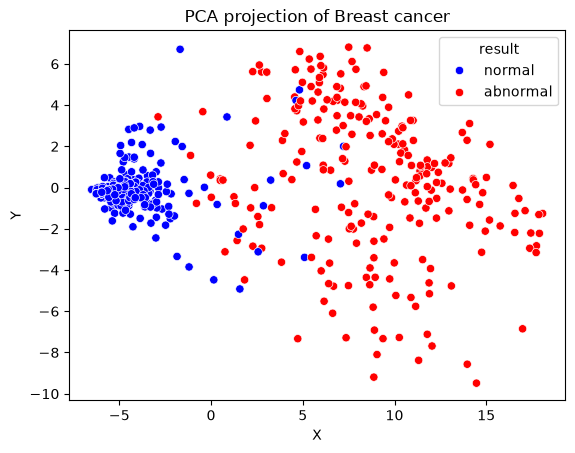

In [74]:
# YOUR ANSWER HERE
# Remove the sample_id column from the dataset
dfb_noid = dfb_noid = dfb.drop(columns=['sample_id'])
plot_projected_dataset(dfb_noid, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What happened when you removed the sample_id feature from the breast cancer dataset?

* When I removed the sample_id feature, the graph changed a lot. The points were no longer squeezed into a vertical line, and we could see their real distribution. Normal samples form a small group on the left, while abnormal samples spread out to the right, making the difference between the two classes much clearer.

Are the abnormal data points outliers? Are they extreme values?

* The abnormal points form a separate and widely spread group on the right side of the graph. They are not simply isolated errors, since many of them belong to the same abnormal cluster. However, some points at the far edges of this group can be considered extreme values compared with the main concentration of normal samples


# 2. Create isolation tree

## 2.1. Random dimension and random split  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement pick_random_dimension.**</font>

In [75]:
def pick_random_dimension(df, columns_to_ignore):
    # YOUR ANSWER HERE
    # Get the columns that are not in the ignore list
    available_columns = [col for col in df.columns if col not in columns_to_ignore]
    
    # Randomly select one available dimension
    dimension = random.choice(available_columns)

    return dimension
    

In [76]:
# LEAVE AS-IS

print("Random dimensions for the 'thyroid' dataset")
print(pick_random_dimension(dft, ["result"]))
print(pick_random_dimension(dft, ["result"]))
print()

print("Random dimensions for the 'cardio' dataset")
print(pick_random_dimension(dfc, ["result"]))
print(pick_random_dimension(dfc, ["result"]))
print()

print("Random dimensions for the 'breast cancer' dataset")
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print()

Random dimensions for the 'thyroid' dataset
free_thyroxine_index
thyroid_binding_globulin

Random dimensions for the 'cardio' dataset
max
min

Random dimensions for the 'breast cancer' dataset
bland_chromatin
bare_nuclei




<font size="+1" color="#2680EB">**Implement pick_random_split.** It should return a random split point chosen uniformly at random between the minimum and the maximum value along a dimension.</font>

In [77]:
def pick_random_split(df, dimension):
    # YOUR ANSWER HERE
    # Get the minimum and maximum values of the selected dimension
    min_value = np.min(df[dimension])
    max_value = np.max(df[dimension])
    # Choose a random split point between the minimum and maximum values
    split_point = random.uniform(min_value, max_value)
    
    return split_point

In [78]:
# LEAVE AS-IS
print("Random splits according to 't3' in the 'thyroid' dataset")
print(pick_random_split(dft, "t3"))
print(pick_random_split(dft, "t3"))
print()

print("Random splits according to 'AC' in the 'cardio' dataset")
print(pick_random_split(dfc, "AC"))
print(pick_random_split(dfc, "AC"))
print()
print("Random splits according to 'mitoses' in the 'breast cancer' dataset")
print(pick_random_split(dfb, "mitoses"))
print(pick_random_split(dfb, "mitoses"))
print()

Random splits according to 't3' in the 'thyroid' dataset
0.007023049130629459
0.11408474021707637

Random splits according to 'AC' in the 'cardio' dataset
-0.6503480005918497
0.20045669777175235

Random splits according to 'mitoses' in the 'breast cancer' dataset
5.701643673580799
6.499901952181624



## 2.2. Implement splitting a dataset into two parts <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement split_dataset.**</font>

In [79]:
def split_dataset(df, dimension, split):
    # YOUR ANSWER HERE
    # Divide the dataset according to the selected dimension and split point
    df1 = df[df[dimension] <= split].copy()
    df2 = df[df[dimension] > split].copy()
    assert len(df1) + len(df2) == len(df), "The split did not preserve the number of rows."
    return (df1, df2)

<font size="+1" color="#2680EB">**Test split_dataset.** Select a dataset, a dimension, and a cut-off, and split the dataset, then print the two pieces and check that the sum of the sizes of the two pieces is the size of the original data.</font>

In [80]:
# (left, right) = split_dataset( ... )

# YOUR ANSWER HERE
left, right = split_dataset(dfc, 'AC', 0.5)


display(left.head(3))
display(right.head(3))

print(f"Sizes: left={len(left)}, right={len(right)}, sum={len(left)+len(right)} (should be {len(dfc)})")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,min,max,nmax,nzeros,mode,mean,median,variance,tendency,result
1,0.110729,-0.079903,-0.203640,1.268942,0.396246,-0.061401,-0.278295,-1.710270,0.759072,-0.420487,...,-0.798376,1.854728,0.278625,0.963083,0.301464,0.129265,0.093563,-0.256385,-0.493294,normal
2,0.216546,-0.272445,-0.203640,1.050988,0.148753,-0.061401,-0.278295,-1.710270,1.106509,-0.420487,...,-1.332931,0.314688,2.342663,-0.488279,0.061002,0.065417,0.024596,-0.256385,1.140018,normal
4,-0.100905,0.363595,1.321366,1.027120,0.141359,-0.061401,-0.278295,-0.992364,-0.051613,-0.420487,...,-0.085638,-0.565334,0.278625,-0.488279,-0.059229,0.065417,0.024596,-0.456787,1.140018,normal


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,min,max,nmax,nzeros,mode,mean,median,variance,tendency,result
0,0.004912,0.693191,-0.203640,0.595322,0.353190,-0.061401,-0.278295,-1.650444,0.759072,-0.420487,...,-0.798376,1.854728,0.622631,0.963083,0.301464,0.193113,0.231498,-0.289786,-0.493294,normal
3,0.004912,0.727346,-0.203640,1.212171,-0.683598,-0.061401,-0.278295,-1.710270,1.106509,-0.420487,...,-1.332931,0.314688,1.654650,-0.488279,0.061002,0.193113,0.093563,-0.323186,1.140018,normal
5,-0.100905,1.375314,4.484914,0.480556,-0.191869,-0.061401,-0.278295,-0.992364,0.064200,-0.420487,...,-0.691466,-0.345328,-0.753395,-0.488279,0.301464,0.256962,0.300465,-0.356586,1.140018,normal


Sizes: left=1297, right=534, sum=1831 (should be 1831)


## 2.3. Create one isolation tree <font color="#2680EB">[20%]</font>

In [81]:
# LEAVE AS-IS

dfti = dft.copy()
dfti.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dft))])
display(dfti.head(5))

dfci = dfc.copy()
dfci.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfc))])
display(dfci.head(5))

# Before adding patient id to the breast cancer dataset,
# we will drop '?' and null values from this dataset, 
# and convert one of the features to numeric.
dfbi = dfb.replace('?', np.nan).dropna().copy()
dfbi['bare_nuclei'] = dfbi['bare_nuclei'].apply(pd.to_numeric)

dfbi.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfbi))])
display(dfbi.head(5))

,id,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
0,P0001,0.73,0.00060,0.015,0.120,0.082,0.146,normal
1,P0002,0.24,0.00025,0.030,0.143,0.133,0.108,normal
2,P0003,0.47,0.00190,0.024,0.102,0.131,0.078,normal
3,P0004,0.64,0.00090,0.017,0.077,0.090,0.085,normal
4,P0005,0.23,0.00025,0.026,0.139,0.090,0.153,normal


,id,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,...,min,max,nmax,nzeros,mode,mean,median,variance,tendency,result
0,P0001,0.004912,0.693191,-0.203640,0.595322,0.353190,-0.061401,-0.278295,-1.650444,0.759072,...,-0.798376,1.854728,0.622631,0.963083,0.301464,0.193113,0.231498,-0.289786,-0.493294,normal
1,P0002,0.110729,-0.079903,-0.203640,1.268942,0.396246,-0.061401,-0.278295,-1.710270,0.759072,...,-0.798376,1.854728,0.278625,0.963083,0.301464,0.129265,0.093563,-0.256385,-0.493294,normal
2,P0003,0.216546,-0.272445,-0.203640,1.050988,0.148753,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,2.342663,-0.488279,0.061002,0.065417,0.024596,-0.256385,1.140018,normal
3,P0004,0.004912,0.727346,-0.203640,1.212171,-0.683598,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,1.654650,-0.488279,0.061002,0.193113,0.093563,-0.323186,1.140018,normal
4,P0005,-0.100905,0.363595,1.321366,1.027120,0.141359,-0.061401,-0.278295,-0.992364,-0.051613,...,-0.085638,-0.565334,0.278625,-0.488279,-0.059229,0.065417,0.024596,-0.456787,1.140018,normal


,id,sample_id,clump_thickness,uniformity_cell_size,uniformity_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,result
0,P0001,1000025,5,1,1,1,2,1,3,1,1,normal
1,P0002,1002945,5,4,4,5,7,10,3,2,1,normal
2,P0003,1015425,3,1,1,1,2,2,3,1,1,normal
3,P0004,1016277,6,8,8,1,3,4,3,7,1,normal
4,P0005,1017023,4,1,1,3,2,1,3,1,1,normal


<font size="+1" color="#2680EB">**Implement isolation_tree.**</font>

In [82]:
def isolation_tree(data, columns_to_ignore, min_items):
    tree = {}
    if len(data) <= min_items:
        return {"contents": data}
    else:
        # YOUR ANSWER HERE
         # Select a random dimension and split point
        dimension = pick_random_dimension(data, columns_to_ignore)
        split = pick_random_split(data, dimension)
        # Divide the dataset into two parts
        left, right = split_dataset(data, dimension, split)

        # We build the left and right subtrees recursively
        tree = {"dimension": dimension,"split": split,"left": isolation_tree(left, columns_to_ignore, min_items),"right": isolation_tree(right, columns_to_ignore, min_items)}
        return tree    

In [83]:
# LEAVE AS-IS

class tree_drawing(object):
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

    def __str__(self, label='', level=0):
        ret = "-" * level + label + ":" + repr(self.value)+"\n"
        if self.left:
            ret += self.left.__str__("<", level+1)
        if self.right:
            ret += self.right.__str__(">", level+1)
        return ret

    def __repr__(self):
        return self.value
    
def tree_to_nodes(tree):
    if 'contents' in tree:
        data = tree['contents']
        normal_count = len(data[data['result'] == 'normal'])
        abnormal_count = len(data[data['result'] == 'abnormal'])
        description = "external node: %d normal + %d abnormal" % (normal_count, abnormal_count)
        return tree_drawing(description)
    else:
        left = tree['left']
        right = tree['right']
        description = 'internal node: ' + tree['dimension'] + ' <= ' + ("%.2f" % tree['split'])
        n = tree_drawing(description, tree_to_nodes(left), tree_to_nodes(right) )
        return n

In [84]:
# LEAVE THIS CODE AS-IS

print("Thyroid dataset:")
mytree_thyroid = isolation_tree(dfti, ['id', 'result'], len(dfti)/2 )
print(tree_to_nodes(mytree_thyroid))

print("Cardiotocography dataset:")
mytree_cardio = isolation_tree(dfci, ['id', 'result'], len(dfci)/2 )
print(tree_to_nodes(mytree_cardio))

print("Breast Cancer dataset:")
mytree_breastcancer = isolation_tree(dfbi, ['id', 'sample_id', 'result'], len(dfbi)/2 )
print(tree_to_nodes(mytree_breastcancer))

Thyroid dataset:
:'internal node: age <= 0.31'
-<:'external node: 1195 normal + 72 abnormal'
->:'internal node: t4_thyroxine <= 0.04'
--<:'external node: 34 normal + 91 abnormal'
-->:'internal node: thyroid_binding_globulin <= 0.30'
---<:'internal node: t4_thyroxine <= 0.05'
----<:'external node: 40 normal + 18 abnormal'
---->:'internal node: tsh <= 0.04'
-----<:'internal node: t3 <= 0.02'
------<:'external node: 1918 normal + 245 abnormal'
------>:'external node: 3458 normal + 87 abnormal'
----->:'external node: 7 normal + 21 abnormal'
--->:'external node: 14 normal + 0 abnormal'

Cardiotocography dataset:
:'internal node: variance <= 4.54'
-<:'internal node: DS <= 0.95'
--<:'internal node: AC <= 3.84'
---<:'internal node: tendency <= -0.85'
----<:'external node: 101 normal + 38 abnormal'
---->:'internal node: MSTV <= 0.21'
-----<:'internal node: nmax <= -1.13'
------<:'external node: 53 normal + 15 abnormal'
------>:'internal node: UC <= 0.38'
-------<:'external node: 667 normal + 54

<font size="+1" color="#2680EB">**Implement function get_max_tree_depth.**</font>

In [85]:

def get_max_tree_depth(tree):    
    if 'contents' in tree:
        return 0
    else:
        # YOUR ANSWER HERE
        left_depth = get_max_tree_depth(tree['left'])
        right_depth = get_max_tree_depth(tree['right'])

        depth = 1 + max(left_depth, right_depth)
        
        return depth

In [86]:
# LEAVE AS-IS

# Testing code
print("Depth of the random tree you built over the 'thyroid' dataset")
print(get_max_tree_depth(mytree_thyroid))
print()


Depth of the random tree you built over the 'thyroid' dataset
6




# 3. Create isolation forests and find depth of items

## 2.1. Create an isolation forest <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement function isolation_forest.**</font>

In [87]:
def isolation_forest(df, columns_to_ignore, min_items, num_trees):
    forest = []
    # YOUR ANSWER HERE
    for i in range(num_trees):
        tree = isolation_tree(df, columns_to_ignore, min_items)
        forest.append(tree)
    
    return forest

In [88]:
# LEAVE AS-IS OR MODIFY IF YOU SEE THAT IT IMPROVES THE SEPARATION BETWEEN CLASSES
# If you change 'min_items' or 'num_trees', indicate here that you have changed them

min_items_thyroid = 50
num_trees_thyroid = 20

myforest_thyroid = isolation_forest(dfti, ['id', 'result'], min_items_thyroid, num_trees_thyroid)
print(f"The 'thyroid' forest has {len(myforest_thyroid)} trees")

min_items_cardio = 50
num_trees_cardio = 20

myforest_cardio = isolation_forest(dfci, ['id', 'result'], min_items_cardio, num_trees_cardio)
print(f"The 'cardio' forest has {len(myforest_cardio)} trees")

min_items_breastcancer = 80
num_trees_breastcancer = 20

myforest_breastcancer = isolation_forest(dfbi, ['id', 'sample_id', 'result'], min_items_breastcancer, num_trees_breastcancer)
print(f"The 'breast cancer' forest has {len(myforest_breastcancer)} trees")

The 'thyroid' forest has 20 trees
The 'cardio' forest has 20 trees
The 'breast cancer' forest has 20 trees


In [89]:
# LEAVE THIS CODE AS-IS

print("Thyroid forest (first two trees)")
print(tree_to_nodes(myforest_thyroid[0]))
print(tree_to_nodes(myforest_thyroid[1]))
print()

print("Cardio forest (first two trees)")
print(tree_to_nodes(myforest_cardio[0]))
print(tree_to_nodes(myforest_cardio[1]))
print()

print("Breast cancer forest (first two trees)")
print(tree_to_nodes(myforest_breastcancer[0]))
print(tree_to_nodes(myforest_breastcancer[1]))
print()


Thyroid forest (first two trees)
:'internal node: free_thyroxine_index <= 0.06'
-<:'internal node: t4_thyroxine <= 0.01'
--<:'external node: 0 normal + 1 abnormal'
-->:'internal node: age <= 0.67'
---<:'internal node: tsh <= 0.02'
----<:'internal node: free_thyroxine_index <= 0.02'
-----<:'external node: 2 normal + 0 abnormal'
----->:'internal node: free_thyroxine_index <= 0.04'
------<:'external node: 6 normal + 0 abnormal'
------>:'internal node: t4_thyroxine <= 0.12'
-------<:'internal node: tsh <= 0.00'
--------<:'internal node: thyroid_binding_globulin <= 0.20'
---------<:'internal node: t4_thyroxine <= 0.09'
----------<:'internal node: tsh <= 0.00'
-----------<:'internal node: thyroid_binding_globulin <= 0.10'
------------<:'external node: 10 normal + 0 abnormal'
------------>:'external node: 47 normal + 0 abnormal'
----------->:'external node: 1 normal + 0 abnormal'
---------->:'external node: 7 normal + 0 abnormal'
--------->:'external node: 1 normal + 0 abnormal'
-------->:'ex

## 3.2. Find the average depth of an item <font color="#2680EB">[10%]</font>

In [90]:
# LEAVE AS-IS

def find_element_depth_aux(tree, column_name, column_value, depth):
    
    if 'contents' in tree:
        # We are in a leaf node
        
        data = tree['contents']
        matching = data[data[column_name] == column_value]
        if len(matching) == 0:
            return None
        elif len(matching) > 1:
            print("Error: multiple elements match your search criterion")
            return None
        else:
            return depth
    else:
        # We are in an internal node
        
        in_left = find_element_depth_aux(tree['left'], column_name, column_value, depth+1)
        if in_left == None:
            in_right = find_element_depth_aux(tree['right'], column_name, column_value, depth+1)
            return in_right
        else:
            return in_left
        
def find_element_depth(tree, column_name, column_value):
    result = find_element_depth_aux(tree, column_name, column_value, 0)
    assert result is not None, f"Element with {column_name}={column_value} not found in the tree."
    return result

In [91]:
# LEAVE AS-IS

def print_sample_depths(df, sample_size, tested_tree):

    for result in ['normal', 'abnormal']:
        print("Depths for %s items" % result)

        sample = list(df[df['result'] == result]['id'].sample(sample_size))

        max_depth = get_max_tree_depth(tested_tree)
        for random_id in sample:
            depth = find_element_depth(tested_tree, 'id', random_id)
            print(f"- id={random_id} is at depth {depth}/{max_depth}")

print(f"Shallow tree for thyroid, having maximum depth {get_max_tree_depth(mytree_thyroid)}")
print_sample_depths(dfti, 10, mytree_thyroid)
print()

print(f"Shallow tree for cardio, having maximum depth {get_max_tree_depth(mytree_cardio)}")
print_sample_depths(dfci, 10, mytree_cardio)
print()

print(f"Shallow tree for breast cancer, having maximum depth {get_max_tree_depth(mytree_breastcancer)}")
print_sample_depths(dfbi, 10, mytree_breastcancer)
print()

Shallow tree for thyroid, having maximum depth 6
Depths for normal items
- id=P2064 is at depth 6/6
- id=P4119 is at depth 6/6
- id=P5106 is at depth 6/6
- id=P3149 is at depth 1/6
- id=P2033 is at depth 4/6
- id=P0270 is at depth 6/6
- id=P6062 is at depth 6/6
- id=P3059 is at depth 6/6
- id=P2382 is at depth 6/6
- id=P4069 is at depth 6/6
Depths for abnormal items
- id=P4396 is at depth 6/6
- id=P6646 is at depth 6/6
- id=P4008 is at depth 2/6
- id=P1778 is at depth 4/6
- id=P5558 is at depth 2/6
- id=P0117 is at depth 2/6
- id=P2589 is at depth 1/6
- id=P2414 is at depth 6/6
- id=P0965 is at depth 2/6
- id=P2132 is at depth 6/6

Shallow tree for cardio, having maximum depth 7
Depths for normal items
- id=P0909 is at depth 6/7
- id=P0154 is at depth 7/7
- id=P0122 is at depth 5/7
- id=P0320 is at depth 7/7
- id=P0660 is at depth 7/7
- id=P0774 is at depth 7/7
- id=P0166 is at depth 7/7
- id=P0543 is at depth 7/7
- id=P0149 is at depth 7/7
- id=P0731 is at depth 5/7
Depths for abnorma

<font size="+1" color="#2680EB">**Answer the following question.**</font>

**Answer:**

What do you observe regarding the depths of normal and abnormal items in these trees?

* In general, abnormal items tend to appear at smaller depths than normal items, but this is not always the case. In the Thyroid dataset, most normal items reach the maximum depth, while some abnormal items are isolated much earlier. However, other abnormal items also reach the maximum depth. In the Cardiotocography dataset, normal and abnormal items have quite similar depths, so it is more difficult to distinguish between the two classes. The Breast Cancer dataset shows the clearest difference. All normal items reach the maximum depth, while abnormal items are isolated much earlier, at depths 1 or 2. Overall, abnormal items are usually easier to isolate, especially in the Breast Cancer dataset. However, the results are not equally clear for all three datasets.

In [92]:
# LEAVE AS-IS

def find_average_depth(forest, column_name, column_value):
    sum_depths = 0
    for i in range(len(forest)):
        depth = find_element_depth(forest[i], column_name, column_value)
        assert depth is not None, f"Element with {column_name}={column_value} not found in tree {i} of the forest."
        sum_depths += depth
    return float(sum_depths)/float(len(forest))

In [93]:
# LEAVE AS-IS

def test_random_elements(df, forest):
    for result in ['normal', 'abnormal']:
        print(f"Average depths for {result} items")

        sample = list(df[df['result'] == result]['id'].sample(5))

        for random_id in sample:
            average_depth = find_average_depth(forest, 'id', random_id)
            print(f"- id={random_id} is at average depth {average_depth:.1f}")
        
print("Testing forest for the 'thyroid' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'cardio' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'breast cancer' dataset")
test_random_elements(dfbi, myforest_breastcancer)
print()


Testing forest for the 'thyroid' dataset
Average depths for normal items
- id=P2596 is at average depth 21.9
- id=P2917 is at average depth 22.0
- id=P6839 is at average depth 20.4
- id=P4800 is at average depth 19.1
- id=P1949 is at average depth 24.4
Average depths for abnormal items
- id=P6550 is at average depth 14.2
- id=P3577 is at average depth 22.2
- id=P5251 is at average depth 20.1
- id=P5566 is at average depth 21.4
- id=P0116 is at average depth 8.1

Testing forest for the 'cardio' dataset
Average depths for normal items
- id=P2808 is at average depth 17.1
- id=P1655 is at average depth 19.7
- id=P3685 is at average depth 23.4
- id=P5813 is at average depth 24.0
- id=P7117 is at average depth 16.9
Average depths for abnormal items
- id=P4968 is at average depth 20.9
- id=P2885 is at average depth 17.9
- id=P3795 is at average depth 21.6
- id=P3513 is at average depth 8.4
- id=P0290 is at average depth 8.6

Testing forest for the 'breast cancer' dataset
Average depths for no

# 4. Find the average depth of a sample of normal and abnormal points

## 4.1. Determine average depths <font color="#2680EB">[10%]</font>

In [94]:
# LEAVE AS-IS

def sample_dataset(df, sample_size):
    abnormal_sample = list(df[df['result'] == 'abnormal']['id'].sample(sample_size))
    normal_sample = list(df[df['result'] == 'normal']['id'].sample(sample_size))
    return abnormal_sample, normal_sample

SAMPLE_SIZE = 30

print("Thyroid dataset")
abnormal_thyroid_sample, normal_thyroid_sample = sample_dataset(dfti, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_thyroid_sample)
print("Abnormal point sample ids : %s" % normal_thyroid_sample)
print()

print("Cardiotocography dataset")
abnormal_cardio_sample, normal_cardio_sample = sample_dataset(dfci, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_cardio_sample)
print("Abnormal point sample ids : %s" % normal_cardio_sample)
print()

print("Breast cancer dataset")
abnormal_breastcancer_sample, normal_breastcancer_sample = sample_dataset(dfbi, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_breastcancer_sample)
print("Abnormal point sample ids : %s" % normal_breastcancer_sample)
print()



Thyroid dataset
Normal point sample ids   : ['P4613', 'P3597', 'P1740', 'P1213', 'P3246', 'P3799', 'P5212', 'P4094', 'P1574', 'P2137', 'P2357', 'P0687', 'P4179', 'P5390', 'P5281', 'P3944', 'P6877', 'P2147', 'P6296', 'P3854', 'P1989', 'P1466', 'P6031', 'P0663', 'P2423', 'P2057', 'P3473', 'P3477', 'P2689', 'P3940']
Abnormal point sample ids : ['P4622', 'P1447', 'P3261', 'P2350', 'P1909', 'P6163', 'P6978', 'P7075', 'P6918', 'P5921', 'P2743', 'P1957', 'P5240', 'P1072', 'P3258', 'P4057', 'P5383', 'P6094', 'P5965', 'P4641', 'P4811', 'P1099', 'P3514', 'P3740', 'P2410', 'P3178', 'P6917', 'P6249', 'P5623', 'P0175']

Cardiotocography dataset
Normal point sample ids   : ['P1820', 'P1791', 'P1696', 'P1761', 'P1763', 'P1702', 'P1814', 'P1725', 'P1821', 'P1817', 'P1816', 'P1693', 'P1736', 'P1772', 'P1745', 'P1759', 'P1764', 'P1782', 'P1765', 'P1734', 'P1740', 'P1669', 'P1828', 'P1679', 'P1723', 'P1790', 'P1762', 'P1710', 'P1667', 'P1671']
Abnormal point sample ids : ['P0020', 'P1520', 'P0111', 'P161

In [95]:
# LEAVE AS-IS

def print_average_depths(forest, sample):
    depths = []
    for i in sample:
        depth = find_average_depth(forest, 'id', i)
        depths.append(depth)
        print(f" element id={i} is at average depth {depth:.2f}")
    return depths

print("THYROID dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_thyroid = print_average_depths(myforest_thyroid, normal_thyroid_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_thyroid = print_average_depths(myforest_thyroid, abnormal_thyroid_sample)
print()

print("CARDIO dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_cardio = print_average_depths(myforest_cardio, normal_cardio_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_cardio = print_average_depths(myforest_cardio, abnormal_cardio_sample)
print()

print("BREAST CANCER dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_breastcancer = print_average_depths(myforest_breastcancer, normal_breastcancer_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_breastcancer = print_average_depths(myforest_breastcancer, abnormal_breastcancer_sample)

THYROID dataset
Depths of items in the 'normal' sample:
 element id=P4622 is at average depth 15.80
 element id=P1447 is at average depth 21.25
 element id=P3261 is at average depth 22.25
 element id=P2350 is at average depth 15.35
 element id=P1909 is at average depth 22.00
 element id=P6163 is at average depth 24.70
 element id=P6978 is at average depth 15.15
 element id=P7075 is at average depth 22.40
 element id=P6918 is at average depth 21.65
 element id=P5921 is at average depth 19.70
 element id=P2743 is at average depth 15.70
 element id=P1957 is at average depth 25.00
 element id=P5240 is at average depth 19.25
 element id=P1072 is at average depth 19.55
 element id=P3258 is at average depth 18.95
 element id=P4057 is at average depth 20.60
 element id=P5383 is at average depth 20.55
 element id=P6094 is at average depth 19.60
 element id=P5965 is at average depth 20.60
 element id=P4641 is at average depth 20.20
 element id=P4811 is at average depth 25.60
 element id=P1099 is

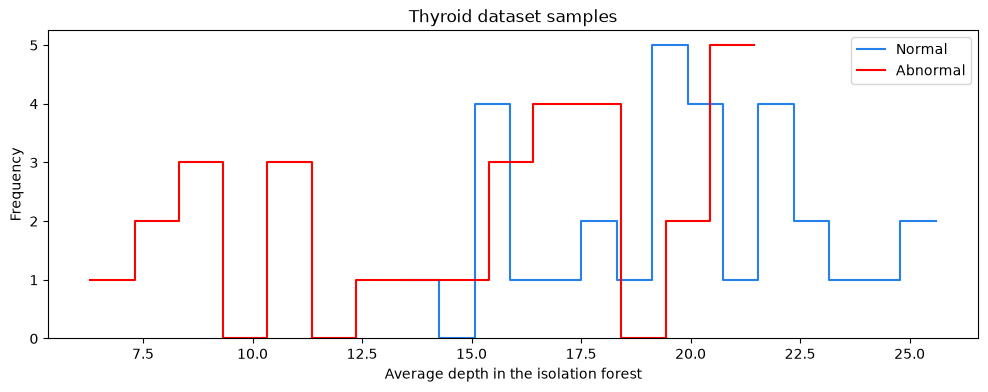

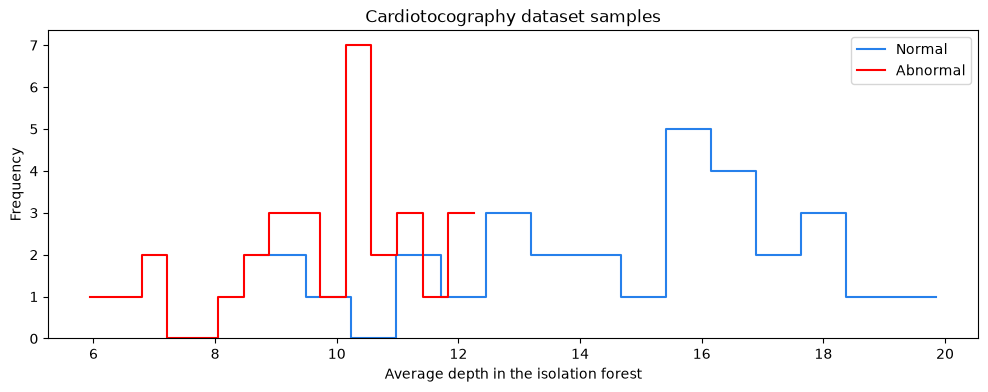

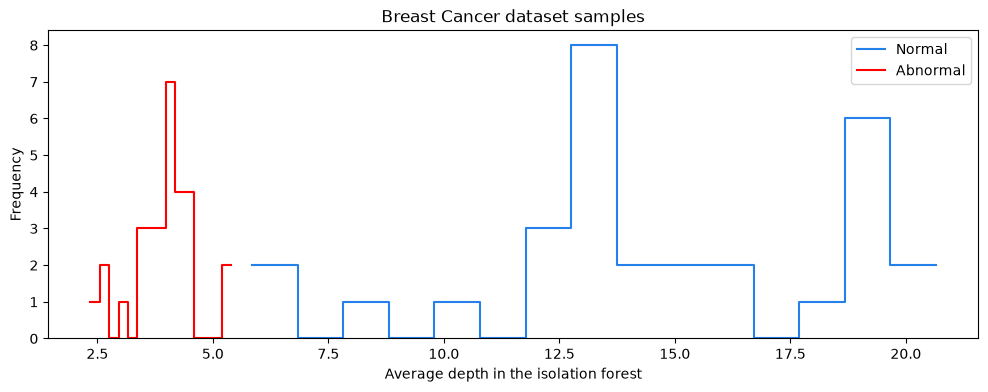

In [96]:
# LEAVE AS-IS

def plot_depth_histogram(normal_depths, abnormal_depths, dataset_name):
    plt.figure(figsize=(12,4))
    sns.histplot(normal_depths, label="Normal", bins=15, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_depths, label="Abnormal", bins=15, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Average depth in the isolation forest")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_depth_histogram(normal_depths_thyroid, abnormal_depths_thyroid, 'Thyroid')
plot_depth_histogram(normal_depths_cardio, abnormal_depths_cardio, 'Cardiotocography')
plot_depth_histogram(normal_depths_breastcancer, abnormal_depths_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of depths of normal and abnormal items in the three datasets? 

* In general, abnormal items tend to have lower average depths compared to normal items, which have higher average depths. This confirms that abnormal points (outliers) are isolated faster by the Isolation Forest.

However, the degree of separation between the two distributions varies depending on the dataset:

- In Breast Cancer, the distinction is very sharp, with abnormal items heavily concentrated around depths 3–5 and normal items distributed around depths 7–11.

- In Cardiotocography, there is a moderate shift; abnormal items peak around depths 7–8, while normal items peak around depths 9–10.

- In Thyroid, both distributions cover a wide range of depths and overlap across most of the depth values (between 10 and 26).

In which of the datasets there is more overlap? In which one there is less overlap?

* The Thyroid dataset has the most overlap. The distributions of normal and abnormal items span across nearly the same depth range, making them difficult to separate purely by depth. Whereas the Breast Cancer dataset has the least overlap. The abnormal and normal items form two clearly distinct groups with only minimal intersection around depths 5.5–6.5.

## 4.2. Compute outlier scores and conclude <font color="#2680EB">[10%]</font>

In [97]:
# LEAVE THIS CODE AS-IS
# Source: https://stackoverflow.com/a/27683292/1235784

from numpy import euler_gamma
from scipy.special import digamma
def harmonic(s):
    return digamma(s + 1) + euler_gamma

In [98]:
# LEAVE THIS CODE AS-IS

def outlier_score_factory(df):
    n = len(df.index)
    c_n = 2.0 * harmonic(n - 1.0) - (2.0 * (n-1)/n)
    return lambda d: 2.0**(-d/c_n)

outlier_score_thyroid = outlier_score_factory(dfti)
outlier_score_cardio = outlier_score_factory(dfci)
outlier_score_breastcancer = outlier_score_factory(dfbi)

# Compute the scores for thyroid
normal_scores_thyroid = [outlier_score_thyroid(d) for d in normal_depths_thyroid]
abnormal_scores_thyroid = [outlier_score_thyroid(d) for d in abnormal_depths_thyroid]

# Compute the scores for cardio
normal_scores_cardio = [outlier_score_cardio(d) for d in normal_depths_cardio]
abnormal_scores_cardio = [outlier_score_cardio(d) for d in abnormal_depths_cardio]

# Compute the scores for breast cancer
normal_scores_breastcancer = [outlier_score_breastcancer(d) for d in normal_depths_breastcancer]
abnormal_scores_breastcancer = [outlier_score_breastcancer(d) for d in abnormal_depths_breastcancer]


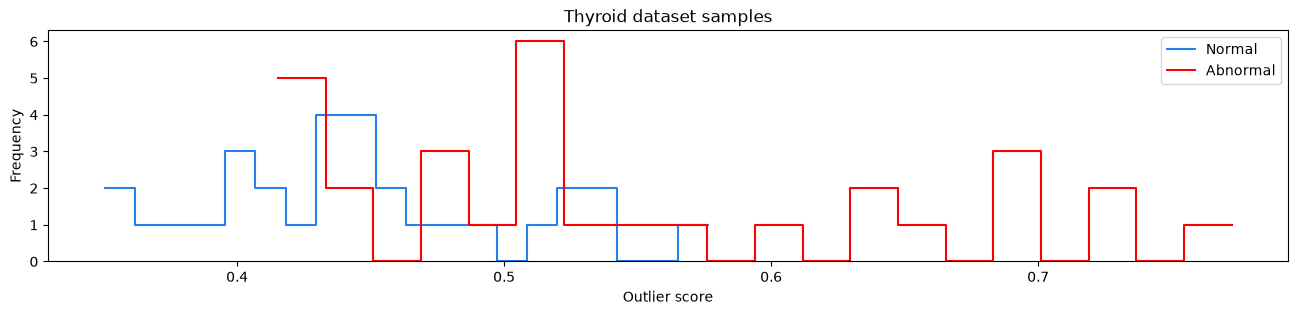

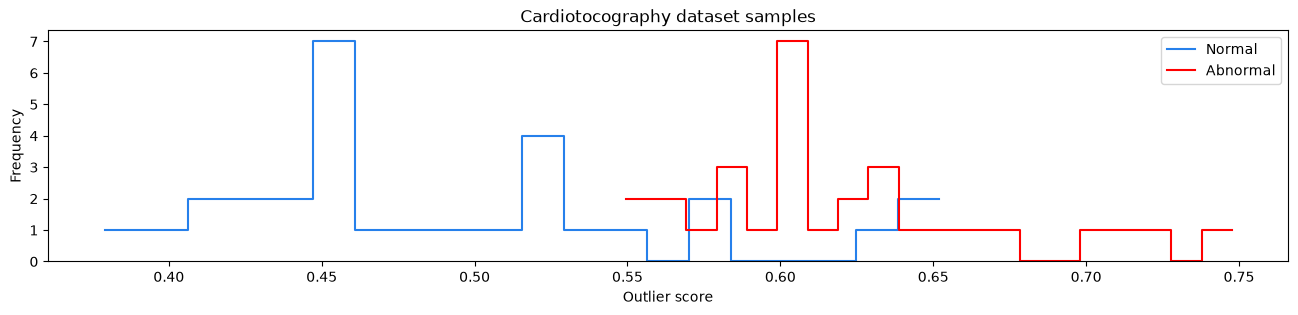

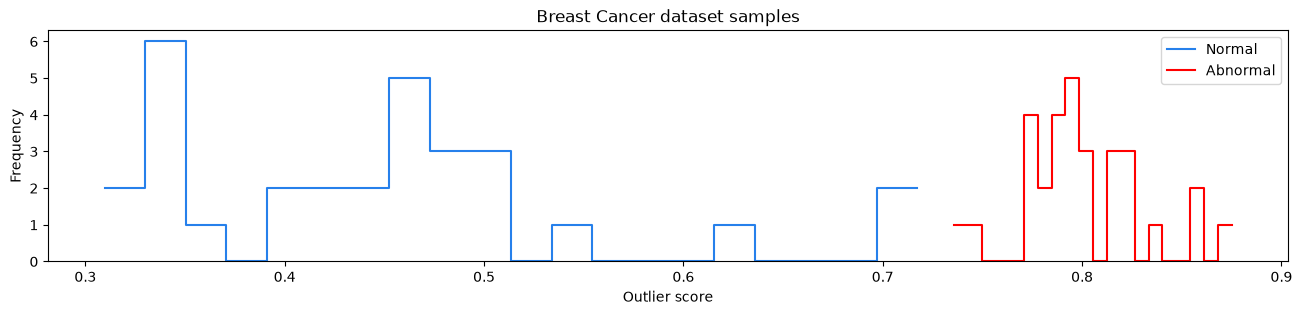

In [99]:
# LEAVE AS-IS

def plot_outlier_score_histogram(normal_scores, abnormal_scores, dataset_name):
    plt.figure(figsize=(16,3))
    sns.histplot(normal_scores, label="Normal", bins=20, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_scores, label="Abnormal", bins=20, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Outlier score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_outlier_score_histogram(normal_scores_thyroid, abnormal_scores_thyroid, 'Thyroid')
plot_outlier_score_histogram(normal_scores_cardio, abnormal_scores_cardio, 'Cardiotocography')
plot_outlier_score_histogram(normal_scores_breastcancer, abnormal_scores_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of outlier scores in the three datasets? 

* Abnormal items tend to have higher outlier scores: Across all three plots, the red curve (abnormal) is consistently shifted toward higher outlier scores compared to the blue curve (normal). This happens because outlier scores are inversely related to depth, so shorter paths result in higher scores

- In Breast Cancer, there is a strong separation between the two classes, with normal points staying mostly below 0.70 and abnormal points reaching values up to ~0.85.   
- In Cardiotocography, abnormal points generally score higher (mostly between 0.66 and 0.80), but there is still partial overlap with normal points around 0.65–0.70.   
- In Thyroid, the scores are much more mixed, showing significant overlap between normal and abnormal items. This makes abnormal cases harder to distinguish.

How would you use it to **detect** outliers? 

* I would define a cutoff threshold for the outlier score, depending on the dataset. Any data point with a score above this threshold would be flagged as a potential outlier (abnormal item), while points below it would be considered normal. For example, in the Breast Cancer dataset, a threshold around 0.70–0.75 could separate most abnormal cases from normal ones.



<font size="+2" color="#2680EB">Additional results: faster method to find all depths</font>

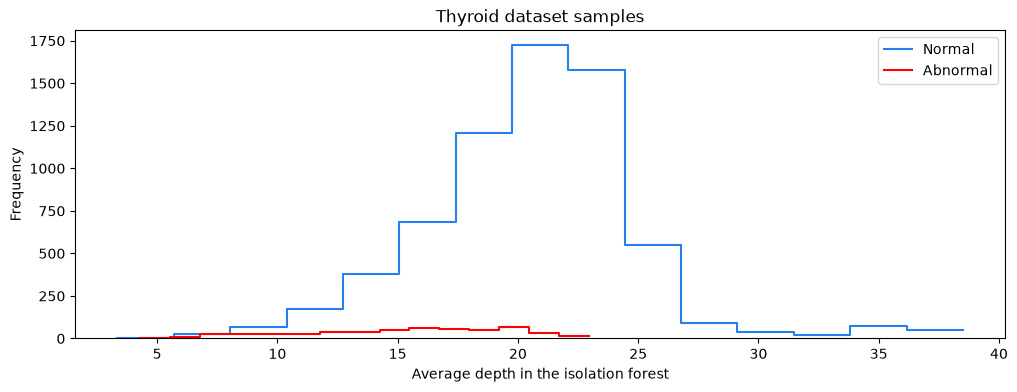

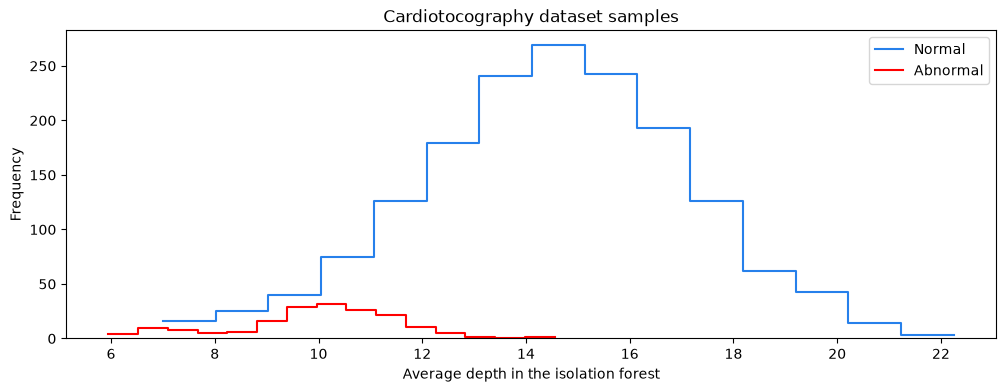

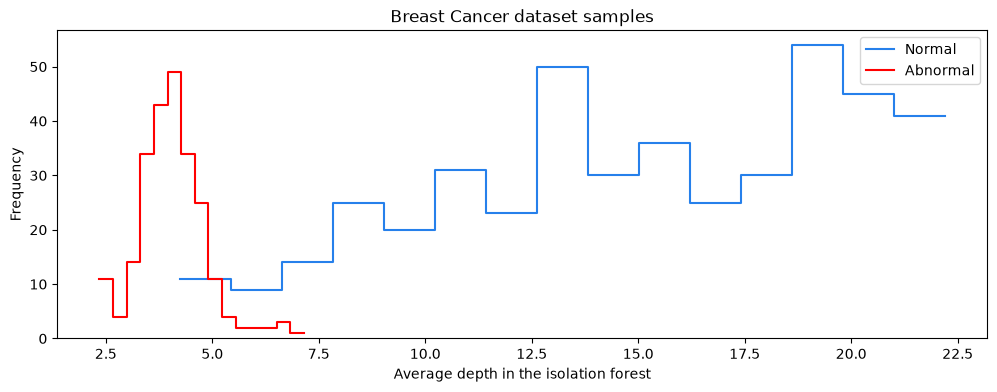

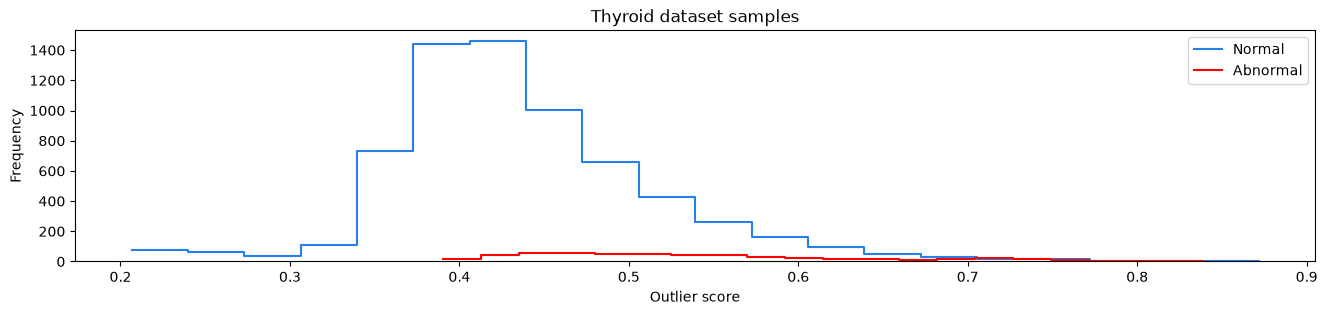

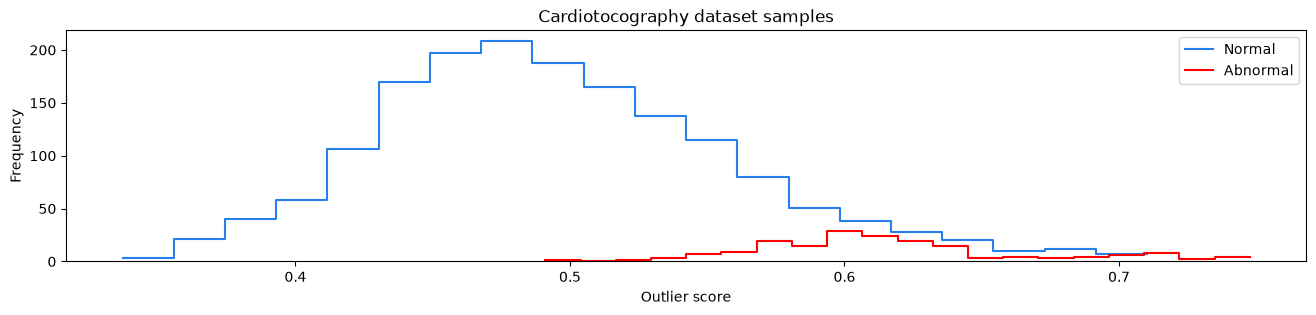

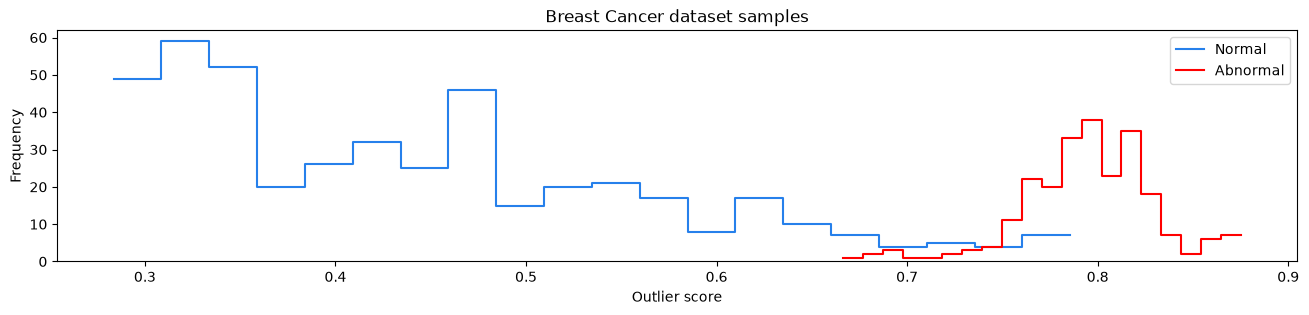

In [100]:
#AI

# Calculate the depth of every item in a tree
def calculate_all_depths(tree, depth=0):
    depths = {}

    if 'contents' in tree:
        for item_id in tree['contents']['id']:
            depths[item_id] = depth
    else:
        depths.update(calculate_all_depths(tree['left'], depth + 1))
        depths.update(calculate_all_depths(tree['right'], depth + 1))

    return depths


# Calculate the average depth of every item in the forest
def calculate_average_depths(forest, df):
    depth_sums = {item_id: 0 for item_id in df['id']}

    for tree in forest:
        tree_depths = calculate_all_depths(tree)

        for item_id, depth in tree_depths.items():
            depth_sums[item_id] += depth

    num_trees = len(forest)

    average_depths = {
        item_id: total_depth / num_trees
        for item_id, total_depth in depth_sums.items()
    }

    return average_depths


# Separate normal and abnormal average depths
def separate_dataset_depths(forest, df):
    average_depths = calculate_average_depths(forest, df)

    normal_depths = [
        average_depths[item_id]
        for item_id in df[df['result'] == 'normal']['id']
    ]

    abnormal_depths = [
        average_depths[item_id]
        for item_id in df[df['result'] == 'abnormal']['id']
    ]

    return normal_depths, abnormal_depths


# Calculate depths for all three datasets
normal_depths_thyroid, abnormal_depths_thyroid = separate_dataset_depths(myforest_thyroid, dfti)

normal_depths_cardio, abnormal_depths_cardio = separate_dataset_depths(myforest_cardio, dfci)

normal_depths_breastcancer, abnormal_depths_breastcancer = separate_dataset_depths(myforest_breastcancer, dfbi)


# Plot average depth histograms
def plot_full_depth_histogram(normal_depths, abnormal_depths, dataset_name):
    plt.figure(figsize=(12, 4))

    sns.histplot(normal_depths, label="Normal", bins=15,
                 stat="count", element="step", fill=False, color="#2680EB")

    sns.histplot(abnormal_depths, label="Abnormal", bins=15,
                 stat="count", element="step", fill=False, color="red")

    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Average depth in the isolation forest")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()


plot_full_depth_histogram(normal_depths_thyroid, abnormal_depths_thyroid, 'Thyroid')

plot_full_depth_histogram(normal_depths_cardio, abnormal_depths_cardio, 'Cardiotocography')

plot_full_depth_histogram(normal_depths_breastcancer, abnormal_depths_breastcancer, 'Breast Cancer')


# Calculate outlier scores
normal_scores_thyroid = [outlier_score_thyroid(depth) for depth in normal_depths_thyroid]
abnormal_scores_thyroid = [outlier_score_thyroid(depth) for depth in abnormal_depths_thyroid]

normal_scores_cardio = [outlier_score_cardio(depth) for depth in normal_depths_cardio]
abnormal_scores_cardio = [outlier_score_cardio(depth) for depth in abnormal_depths_cardio]

normal_scores_breastcancer = [outlier_score_breastcancer(depth) for depth in normal_depths_breastcancer]
abnormal_scores_breastcancer = [outlier_score_breastcancer(depth) for depth in abnormal_depths_breastcancer]


# Plot outlier score histograms
def plot_full_outlier_histogram(normal_scores, abnormal_scores, dataset_name):
    plt.figure(figsize=(16, 3))

    sns.histplot(normal_scores, label="Normal", bins=20,
                 stat="count", element="step", fill=False, color="#2680EB")

    sns.histplot(abnormal_scores, label="Abnormal", bins=20,
                 stat="count", element="step", fill=False, color="red")

    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Outlier score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()


plot_full_outlier_histogram(normal_scores_thyroid, abnormal_scores_thyroid, 'Thyroid')

plot_full_outlier_histogram(normal_scores_cardio, abnormal_scores_cardio, 'Cardiotocography')

plot_full_outlier_histogram(normal_scores_breastcancer, abnormal_scores_breastcancer, 'Breast Cancer')

**Observations and conclusion:**

The histograms show the average depths of all patients in the three datasets, instead of only using random samples. This gives us a better view of how normal and abnormal patients are distributed. In general, abnormal patients tend to have smaller average depths than normal patients. This means that they are usually isolated faster by the Isolation Forest. The difference between the two classes is clearer in the Breast Cancer dataset, where there is less overlap. In the Thyroid and Cardiotocography datasets, the distributions overlap more, so it is harder to distinguish between normal and abnormal patients using only their average depths. Overall, using all the patients gives us a more complete view of the results and helps us compare the separation between normal and abnormal cases in each dataset.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>